# Huấn luyện TwinLiteNet cho phân đoạn mặt đường (Drivable Area)

Notebook này huấn luyện **TwinLiteNet – nhánh Drivable Area (DA)** trên các cặp ảnh-mask nhị phân hợp lệ. Thư mục ảnh có thể chứa ảnh chưa được gán nhãn; các ảnh không có mask tương ứng sẽ tự động bị loại khỏi train/validation.

## Cấu trúc dữ liệu đang sử dụng

```text
/kaggle/input/datasets/tamkhanh/label-v3/test/
├── road-v2/
│   ├── 100.jpg
│   ├── 101.jpg
│   └── ...
└── masks/
    ├── 100_mask.png
    ├── 101_mask.png
    └── ...
```

Quy tắc ghép: `100.jpg` ↔ `100_mask.png`.

## Quy ước mask

- Pixel trắng (`>127`) = mặt đường, class `1`.
- Pixel đen (`≤127`) = nền/không phải mặt đường, class `0`.
- Mask được resize bằng `INTER_NEAREST` để không tạo nhãn trung gian.

**Lưu ý:** Vì dữ liệu hiện chỉ nằm trong thư mục `test`, notebook sẽ tự chia ngẫu nhiên thành 80% train và 20% validation. Do đó, 20% validation này không phải test set độc lập và không nên báo cáo như kết quả test cuối cùng.

Notebook dùng mã nguồn chính thức [chequanghuy/TwinLiteNet](https://github.com/chequanghuy/TwinLiteNet). Repo cần được clone, vì vậy hãy bật **Internet** trong Kaggle Notebook. Không cài `requirements.txt` nguyên bản của repo vì file này ghim PyTorch 1.8.0 và các phiên bản package cũ; notebook dùng PyTorch đã có trong môi trường Kaggle.


In [1]:
# 1. Import thư viện và thiết lập seed
!pip install -q albumentations
import os
import sys
import random
import subprocess
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Cho phép cuDNN tự chọn thuật toán phù hợp với kích thước input cố định.
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
Device: cuda
GPU: Tesla T4


In [2]:
# 2. Cấu hình đường dẫn và siêu tham số

DATASET_ROOT = Path("/kaggle/input/datasets/tamkhanh/label-v3/test")
IMAGE_DIR = DATASET_ROOT / "road-v2"
MASK_DIR = DATASET_ROOT / "masks"

# TwinLiteNet gốc sử dụng input 320x180 (width x height).
IMAGE_WIDTH = 320
IMAGE_HEIGHT = 184

TRAIN_RATIO = 0.80
BATCH_SIZE = 4
EPOCHS = 60
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 5e-4
NUM_WORKERS = 2
USE_AMP = True               # Mixed precision khi chạy GPU
EARLY_STOPPING_PATIENCE = 15 # dừng nếu IoU validation không cải thiện

# Đường dẫn lưu kết quả trong Kaggle.
OUTPUT_DIR = Path("/kaggle/working/twinlite_road_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT = OUTPUT_DIR / "best_model.pth"
LAST_CHECKPOINT = OUTPUT_DIR / "last_checkpoint.pth"
HISTORY_CSV = OUTPUT_DIR / "training_history.csv"

# Nếu muốn tiếp tục huấn luyện từ checkpoint, thay None bằng đường dẫn checkpoint.
RESUME_FROM = None

REPO_URL = "https://github.com/chequanghuy/TwinLiteNet.git"
REPO_DIR = Path("/kaggle/working/TwinLiteNet")

print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)
print("Output directory:", OUTPUT_DIR)


Image directory: /kaggle/input/datasets/tamkhanh/label-v3/test/road-v2
Mask directory: /kaggle/input/datasets/tamkhanh/label-v3/test/masks
Output directory: /kaggle/working/twinlite_road_training


In [3]:
# 3. Kiểm tra dữ liệu và ghép các cặp ảnh-mask
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục ảnh: {IMAGE_DIR}")
if not MASK_DIR.is_dir():
    raise FileNotFoundError(f"Không tìm thấy thư mục mask: {MASK_DIR}")

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
image_files = sorted(
    p for p in IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
)
mask_files = sorted(
    p for p in MASK_DIR.iterdir()
    if p.is_file() and p.name.lower().endswith("_mask.png")
)

# Ghép theo stem: 100.jpg <-> 100_mask.png.
# Không yêu cầu mọi ảnh đều phải có mask vì thư mục có ảnh chưa gán nhãn.
image_by_stem = {}
duplicate_image_stems = []
for image_path in image_files:
    if image_path.stem in image_by_stem:
        duplicate_image_stems.append(image_path.stem)
    else:
        image_by_stem[image_path.stem] = image_path

if duplicate_image_stems:
    examples = sorted(set(duplicate_image_stems))[:10]
    raise RuntimeError(
        "Có nhiều ảnh cùng stem nhưng khác phần mở rộng; cần xử lý để tránh ghép mơ hồ: "
        f"{examples}"
    )

mask_by_stem = {}
duplicate_mask_stems = []
for mask_path in mask_files:
    mask_stem = mask_path.name[:-len("_mask.png")]
    if mask_stem in mask_by_stem:
        duplicate_mask_stems.append(mask_stem)
    else:
        mask_by_stem[mask_stem] = mask_path

if duplicate_mask_stems:
    examples = sorted(set(duplicate_mask_stems))[:10]
    raise RuntimeError(f"Có nhiều mask trùng tên gốc: {examples}")

pairs = []
unlabeled_images = []
for stem, image_path in image_by_stem.items():
    mask_path = mask_by_stem.get(stem)
    if mask_path is None:
        unlabeled_images.append(image_path.name)
    else:
        pairs.append((image_path, mask_path))

orphan_masks = [
    mask_path.name
    for stem, mask_path in mask_by_stem.items()
    if stem not in image_by_stem
]
pairs.sort(key=lambda pair: pair[0].name)

print(f"Tổng số ảnh: {len(image_files)}")
print(f"Tổng số mask: {len(mask_files)}")
print(f"Số cặp ảnh-mask khớp tên: {len(pairs)}")
print(f"Ảnh không có mask (không dùng để train): {len(unlabeled_images)}")
print(f"Mask không có ảnh tương ứng (bỏ qua): {len(orphan_masks)}")
if unlabeled_images[:10]:
    print("Một số ảnh chưa có nhãn:", unlabeled_images[:10])
if orphan_masks[:10]:
    print("Một số mask không có ảnh:", orphan_masks[:10])

if len(pairs) < 2:
    raise RuntimeError(
        "Không đủ cặp ảnh-mask để chia train/validation. "
        "Quy tắc ghép hiện tại: image.jpg phải có mask image_mask.png."
    )

# Đọc thử từng cặp để bỏ các file hỏng trước khi chia dữ liệu.
valid_pairs = []
bad_pairs = []
for image_path, mask_path in tqdm(pairs, desc="Kiểm tra file"):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if image is None or mask is None:
        bad_pairs.append((image_path.name, mask_path.name))
    else:
        valid_pairs.append((image_path, mask_path))

print(f"Cặp đọc được: {len(valid_pairs)}")
print(f"Cặp lỗi, bị loại: {len(bad_pairs)}")
if bad_pairs[:10]:
    print("Một số cặp lỗi:", bad_pairs[:10])
if len(valid_pairs) < 2:
    raise RuntimeError("Còn ít hơn 2 cặp ảnh-mask hợp lệ sau bước kiểm tra.")

pairs = valid_pairs


Tổng số ảnh: 4665
Tổng số mask: 1497
Số cặp ảnh-mask khớp tên: 1455
Ảnh không có mask (không dùng để train): 3210
Mask không có ảnh tương ứng (bỏ qua): 42
Một số ảnh chưa có nhãn: ['100.jpg', '101.jpg', '102.jpg', '103.jpg', '104.jpg', '105.jpg', '106.jpg', '107.jpg', '108.jpg', '109.jpg']
Một số mask không có ảnh: ['1468_mask.png', '1469_mask.png', '1470_mask.png', '1471_mask.png', '1472_mask.png', '1473_mask.png', '1474_mask.png', '1475_mask.png', '1476_mask.png', '1477_mask.png']


Kiểm tra file:   0%|          | 0/1455 [00:00<?, ?it/s]

Cặp đọc được: 1455
Cặp lỗi, bị loại: 0


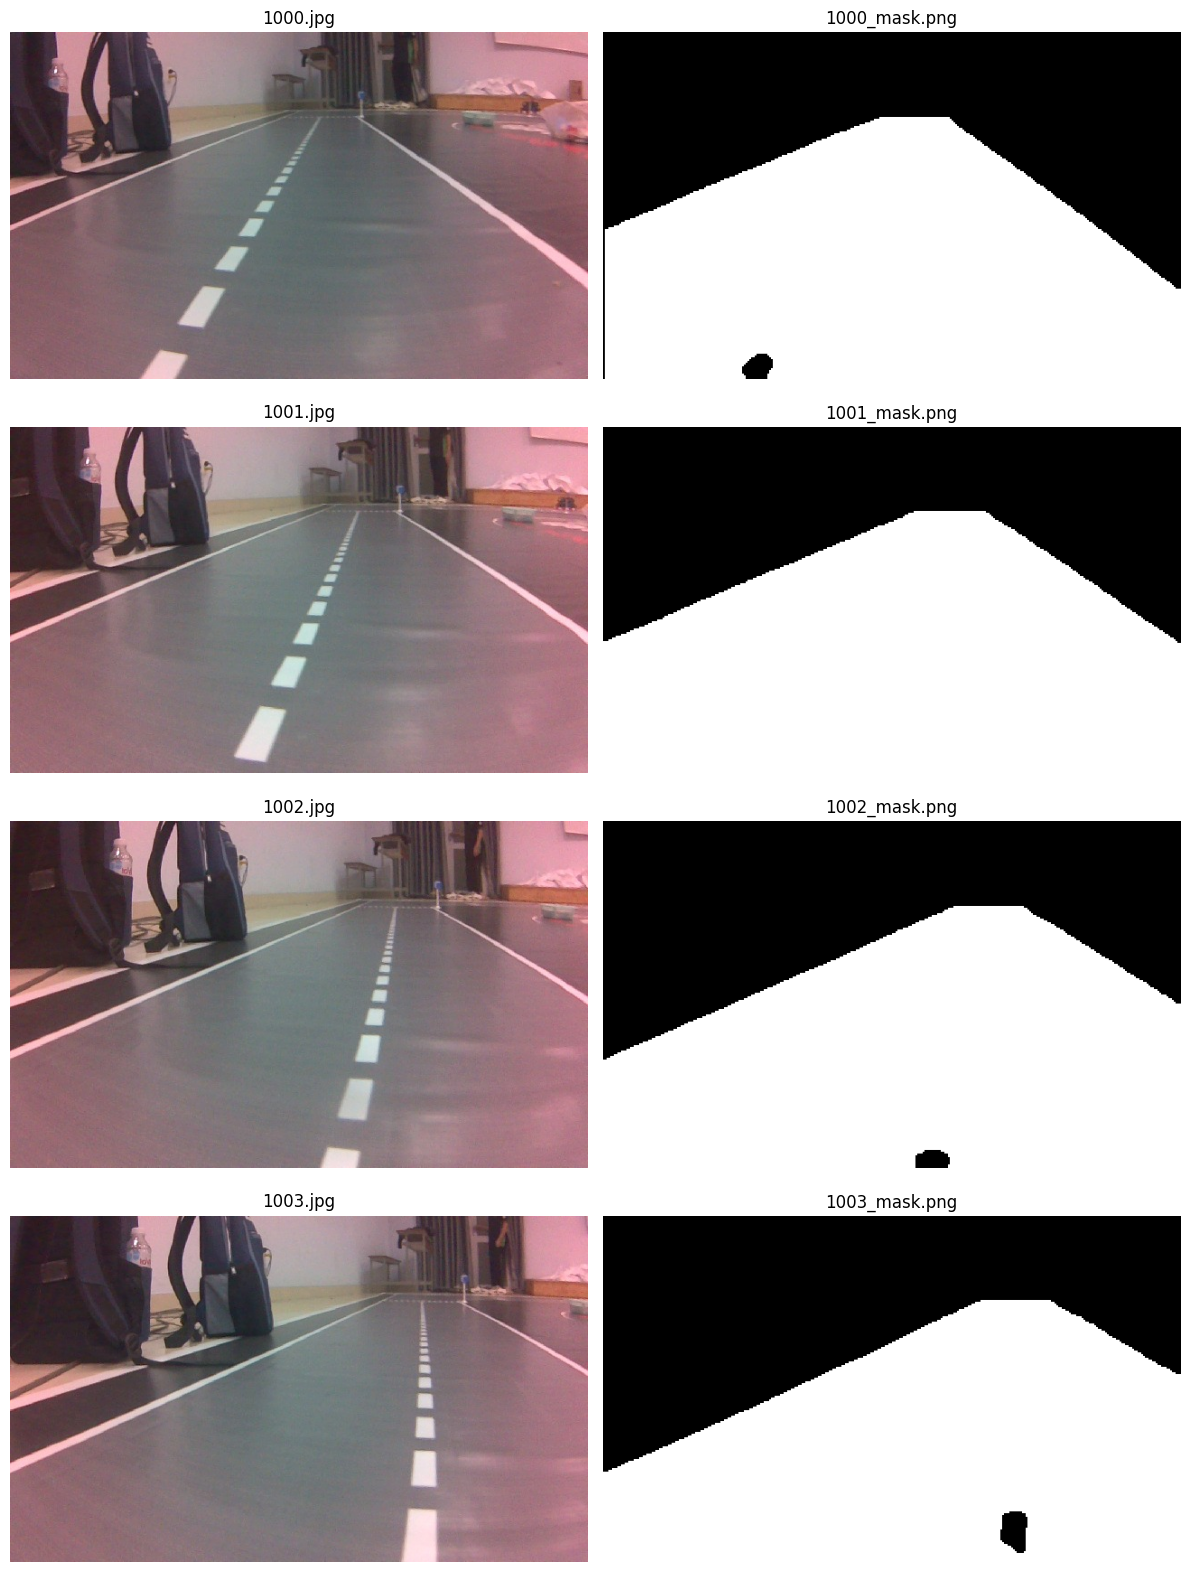

1000_mask.png: road=57.3%, background=42.7%
1001_mask.png: road=58.8%, background=41.2%
1002_mask.png: road=57.8%, background=42.2%
1003_mask.png: road=55.9%, background=44.1%
1004_mask.png: road=53.3%, background=46.7%
1005_mask.png: road=50.6%, background=49.4%
1006_mask.png: road=49.8%, background=50.2%
1007_mask.png: road=50.5%, background=49.5%
1008_mask.png: road=53.2%, background=46.8%
1009_mask.png: road=54.8%, background=45.2%

Hãy kiểm tra trực quan: vùng đường cần trắng, vùng không phải đường cần đen.


In [4]:
# 4. Kiểm tra nhanh một số mask trước khi huấn luyện

def show_pairs(pair_list, n=4):
    n = min(n, len(pair_list))
    fig, axes = plt.subplots(n, 2, figsize=(12, 4 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, (image_path, mask_path) in enumerate(pair_list[:n]):
        image_bgr = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        axes[i, 0].imshow(image_rgb)
        axes[i, 0].set_title(image_path.name)
        axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=255)
        axes[i, 1].set_title(mask_path.name)
        axes[i, 0].axis("off")
        axes[i, 1].axis("off")
    plt.tight_layout()
    plt.show()

show_pairs(pairs, n=4)

# Thống kê tỷ lệ pixel đường/nền của một vài mask.
for image_path, mask_path in pairs[:min(10, len(pairs))]:
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    road_ratio = float((mask > 127).mean())
    print(f"{mask_path.name}: road={road_ratio:.1%}, background={1-road_ratio:.1%}")

print("\nHãy kiểm tra trực quan: vùng đường cần trắng, vùng không phải đường cần đen.")


In [5]:
# 5. Chia train/validation ngẫu nhiên theo tỷ lệ 80/20
rng = np.random.default_rng(SEED)
indices = rng.permutation(len(pairs))

n_val = max(1, int(round(len(pairs) * (1.0 - TRAIN_RATIO))))
n_train = len(pairs) - n_val
if n_train < 1:
    raise RuntimeError("Không đủ dữ liệu cho tập train.")

train_indices = indices[:n_train]
val_indices = indices[n_train:]
train_pairs = [pairs[i] for i in train_indices]
val_pairs = [pairs[i] for i in val_indices]

print(f"Tổng số cặp được dùng: {len(pairs)}")
print(f"Train:      {len(train_pairs)} ({len(train_pairs)/len(pairs):.1%})")
print(f"Validation: {len(val_pairs)} ({len(val_pairs)/len(pairs):.1%})")
print("Chỉ các cặp có cả ảnh và mask mới được đưa vào hai tập này.")


Tổng số cặp được dùng: 1455
Train:      1164 (80.0%)
Validation: 291 (20.0%)
Chỉ các cặp có cả ảnh và mask mới được đưa vào hai tập này.


In [6]:
# 6. Dataset PyTorch (Cải tiến với Albumentations)
import albumentations as A

# Định nghĩa các phép biến đổi dữ liệu cho tập Train
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.5),        # Thay đổi độ sáng/tương phản
    A.RandomShadow(p=0.3),                    # Giả lập bóng râm đổ lên đường
    A.GaussianBlur(blur_limit=(3, 7), p=0.2), # Giả lập camera bị rung/mờ
])

class RoadDataset(Dataset):
    def __init__(self, pair_list, training=False):
        self.pair_list = pair_list
        self.training = training

    def __len__(self):
        return len(self.pair_list)

    def __getitem__(self, index):
        image_path, mask_path = self.pair_list[index]

        # OpenCV đọc ảnh theo thứ tự BGR.
        image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise RuntimeError(f"Không đọc được: {image_path} hoặc {mask_path}")

        image = cv2.resize(
            image, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_LINEAR
        )
        mask = cv2.resize(
            mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST
        )
        
        # Chuyển mask sang dạng nhị phân 0/1 và uint8 để Albumentations xử lý
        mask = (mask > 127).astype(np.uint8)

        # Áp dụng Augmentation đồng bộ ảnh và mask
        if self.training:
            augmented = train_transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # BGR -> RGB; TwinLiteNet gốc dùng tensor float trong [0, 1].
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = np.ascontiguousarray(image.transpose(2, 0, 1))
        image = torch.from_numpy(image).float() / 255.0

        # Mask nhị phân: trắng là đường (class 1), đen là nền (class 0).
        mask = torch.from_numpy(np.ascontiguousarray(mask)).long()

        return image, mask

train_dataset = RoadDataset(train_pairs, training=True)
val_dataset = RoadDataset(val_pairs, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False,
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False,
    persistent_workers=(NUM_WORKERS > 0),
)

images, masks = next(iter(train_loader))
print("Image batch:", images.shape, images.dtype, float(images.min()), float(images.max()))
print("Mask batch:", masks.shape, masks.dtype, "classes:", torch.unique(masks).tolist())

Image batch: torch.Size([4, 3, 184, 320]) torch.float32 0.0 1.0
Mask batch: torch.Size([4, 184, 320]) torch.int64 classes: [0, 1]


In [7]:
# 7. Cài/clone mã nguồn TwinLiteNet chính thức
if not REPO_DIR.exists():
    print("Đang clone TwinLiteNet...")
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    print("Đã tìm thấy repo:", REPO_DIR)

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

try:
    from model.TwinLite import TwinLiteNet
except Exception as exc:
    raise ImportError(
        "Không import được TwinLiteNet. Kiểm tra Kaggle Internet và trạng thái clone repo."
    ) from exc

print("Đã import TwinLiteNet từ:", REPO_DIR / "model" / "TwinLite.py")


Đã tìm thấy repo: /kaggle/working/TwinLiteNet
Đã import TwinLiteNet từ: /kaggle/working/TwinLiteNet/model/TwinLite.py


In [8]:
# 8. Khởi tạo mô hình và kiểm tra kích thước đầu ra
model = TwinLiteNet().to(DEVICE)

with torch.no_grad():
    dummy = torch.zeros(1, 3, IMAGE_HEIGHT, IMAGE_WIDTH, device=DEVICE)
    da_logits, ll_logits = model(dummy)

print("DA output:", tuple(da_logits.shape))
print("LL output:", tuple(ll_logits.shape))

if da_logits.shape[1] != 2:
    raise RuntimeError(f"DA head phải có 2 class, nhưng nhận {da_logits.shape[1]}.")
if tuple(da_logits.shape[-2:]) != (IMAGE_HEIGHT, IMAGE_WIDTH):
    raise RuntimeError(
        "Kích thước đầu ra DA không khớp mask: "
        f"{tuple(da_logits.shape[-2:])} vs {(IMAGE_HEIGHT, IMAGE_WIDTH)}"
    )

# Chỉ dùng da_logits (đầu ra thứ nhất). Không huấn luyện nhánh Lane Line
# vì dataset hiện không có nhãn lane line riêng.
num_params = sum(p.numel() for p in model.parameters())
print(f"Tổng số tham số TwinLiteNet: {num_params:,}")


DA output: (1, 2, 184, 320)
LL output: (1, 2, 184, 320)
Tổng số tham số TwinLiteNet: 439,633


In [9]:
# 9. Tính trọng số class và khởi tạo Loss (Kết hợp CE + Dice)
class_counts = np.zeros(2, dtype=np.int64)
for _, mask_path in tqdm(train_pairs, desc="Đếm pixel train"):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    mask = cv2.resize(mask, (IMAGE_WIDTH, IMAGE_HEIGHT), interpolation=cv2.INTER_NEAREST)
    binary = (mask > 127).astype(np.uint8)
    class_counts[0] += int((binary == 0).sum())
    class_counts[1] += int((binary == 1).sum())

if np.any(class_counts == 0):
    raise RuntimeError(
        f"Tập train thiếu một class: counts={class_counts.tolist()}. "
        "Kiểm tra lại mask và quy ước trắng/đen."
    )

class_weights_np = class_counts.sum() / (2.0 * class_counts.astype(np.float64))
class_weights_np = class_weights_np / class_weights_np.mean()
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)

print("Pixel counts [background, road]:", class_counts.tolist())
print("Class weights [background, road]:", class_weights.tolist())

# --- ĐỊNH NGHĨA DICE LOSS ---
class DiceLoss(nn.Module):
    def __init__(self):
        super(DiceLoss, self).__init__()
    def forward(self, inputs, targets):
        inputs = torch.softmax(inputs, dim=1)
        targets_one_hot = nn.functional.one_hot(targets, num_classes=2).permute(0, 3, 1, 2).float()
        intersection = (inputs * targets_one_hot).sum(dim=(2, 3))
        union = inputs.sum(dim=(2, 3)) + targets_one_hot.sum(dim=(2, 3))
        dice = (2. * intersection + 1e-6) / (union + 1e-6)
        return 1 - dice.mean()

# Khởi tạo 2 hàm loss
criterion_ce = nn.CrossEntropyLoss(weight=class_weights)
criterion_dice = DiceLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=5
)

AMP_ENABLED = bool(USE_AMP and DEVICE.type == "cuda")
scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED) # Sửa lỗi deprecated luôn
print("Mixed precision:", AMP_ENABLED)

Đếm pixel train:   0%|          | 0/1164 [00:00<?, ?it/s]

Pixel counts [background, road]: [34044337, 34491983]
Class weights [background, road]: [1.0065314769744873, 0.9934684634208679]
Mixed precision: True


/tmp/ipykernel_550/2271303974.py:49: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED) # Sửa lỗi deprecated luôn


In [10]:
# 10. Hàm tính metric phân đoạn nhị phân
@torch.no_grad()
def segmentation_metrics(confusion):
    confusion = confusion.float()
    intersection = torch.diag(confusion)
    union = confusion.sum(0) + confusion.sum(1) - intersection
    iou = intersection / union.clamp_min(1.0)

    tp = confusion[1, 1]
    fp = confusion[0, 1]
    fn = confusion[1, 0]

    road_precision = tp / (tp + fp).clamp_min(1.0)
    road_recall = tp / (tp + fn).clamp_min(1.0)
    road_dice = (2 * tp) / (2 * tp + fp + fn).clamp_min(1.0)
    pixel_accuracy = intersection.sum() / confusion.sum().clamp_min(1.0)

    return {
        "background_iou": float(iou[0].item()),
        "road_iou": float(iou[1].item()),
        "mean_iou": float(iou.mean().item()),
        "pixel_accuracy": float(pixel_accuracy.item()),
        "road_precision": float(road_precision.item()),
        "road_recall": float(road_recall.item()),
        "road_dice": float(road_dice.item()),
    }


def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    total_images = 0
    confusion = torch.zeros((2, 2), dtype=torch.long, device=DEVICE)

    progress = tqdm(loader, desc="Train" if training else "Validation", leave=False)
    for images, targets in progress:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        batch_size = images.size(0)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            # Sử dụng cú pháp torch.amp mới để hết cảnh báo
            with torch.amp.autocast('cuda', enabled=AMP_ENABLED):
                outputs = model(images)
                da_logits = outputs[0]
                if da_logits.shape[-2:] != targets.shape[-2:]:
                    da_logits = nn.functional.interpolate(
                        da_logits,
                        size=targets.shape[-2:],
                        mode="bilinear",
                        align_corners=False,
                    )
                
                # --- SỬ DỤNG KẾT HỢP 2 LOSS ---
                loss = criterion_ce(da_logits, targets) + criterion_dice(da_logits, targets)

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()

        total_loss += float(loss.detach().item()) * batch_size
        total_images += batch_size

        predictions = torch.argmax(da_logits.detach(), dim=1)
        bins = torch.bincount(
            (targets.reshape(-1) * 2 + predictions.reshape(-1)), minlength=4
        ).reshape(2, 2)
        confusion += bins

        progress.set_postfix(loss=f"{loss.item():.4f}")

    metrics = segmentation_metrics(confusion)
    metrics["loss"] = total_loss / max(total_images, 1)
    return metrics

In [11]:
# 11. Huấn luyện và lưu checkpoint tốt nhất
start_epoch = 0
best_val_road_iou = -1.0
no_improve_epochs = 0
history = []

if RESUME_FROM is not None:
    resume_path = Path(RESUME_FROM)
    if not resume_path.is_file():
        raise FileNotFoundError(f"Không tìm thấy checkpoint resume: {resume_path}")
    checkpoint = torch.load(resume_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    if "scheduler_state_dict" in checkpoint:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    if "scaler_state_dict" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = int(checkpoint.get("epoch", 0))
    best_val_road_iou = float(checkpoint.get("best_val_road_iou", -1.0))
    print(f"Resume từ epoch {start_epoch}; best road IoU={best_val_road_iou:.4f}")

for epoch in range(start_epoch, EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")
    current_lr = optimizer.param_groups[0]["lr"]
    print(f"Learning rate: {current_lr:.2e}")

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)
    scheduler.step(val_metrics["road_iou"])

    row = {"epoch": epoch + 1, "lr": current_lr}
    row.update({f"train_{k}": v for k, v in train_metrics.items()})
    row.update({f"val_{k}": v for k, v in val_metrics.items()})
    history.append(row)

    print(
        f"Train loss={train_metrics['loss']:.4f} | "
        f"Val loss={val_metrics['loss']:.4f} | "
        f"Val road IoU={val_metrics['road_iou']:.4f} | "
        f"Val mIoU={val_metrics['mean_iou']:.4f} | "
        f"Val Dice={val_metrics['road_dice']:.4f}"
    )

    checkpoint_data = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_val_road_iou": max(best_val_road_iou, val_metrics["road_iou"]),
        "image_width": IMAGE_WIDTH,
        "image_height": IMAGE_HEIGHT,
        "class_names": ["background", "road"],
    }
    torch.save(checkpoint_data, LAST_CHECKPOINT)

    if val_metrics["road_iou"] > best_val_road_iou:
        best_val_road_iou = val_metrics["road_iou"]
        no_improve_epochs = 0
        checkpoint_data["best_val_road_iou"] = best_val_road_iou
        torch.save(checkpoint_data, BEST_CHECKPOINT)
        print(f"Đã lưu best checkpoint: {BEST_CHECKPOINT}")
    else:
        no_improve_epochs += 1

    # Lưu history sau mỗi epoch để tránh mất toàn bộ log nếu runtime bị ngắt.
    import pandas as pd
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)

    if no_improve_epochs >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping: road IoU không cải thiện trong {EARLY_STOPPING_PATIENCE} epoch.")
        break

print("\nTraining hoàn tất.")
print("Best checkpoint:", BEST_CHECKPOINT)
print("Last checkpoint:", LAST_CHECKPOINT)
print("Best validation road IoU:", best_val_road_iou)



Epoch 1/60
Learning rate: 5.00e-04


Train:   0%|          | 0/291 [00:00<?, ?it/s]

Validation:   0%|          | 0/73 [00:00<?, ?it/s]

Train loss=0.6401 | Val loss=0.4246 | Val road IoU=0.9269 | Val mIoU=0.9272 | Val Dice=0.9621
Đã lưu best checkpoint: /kaggle/working/twinlite_road_training/best_model.pth

Epoch 2/60
Learning rate: 5.00e-04


Train:   0%|          | 0/291 [00:00<?, ?it/s]

Validation:   0%|          | 0/73 [00:00<?, ?it/s]

... (171 outputs left out)

Train loss=0.0233 | Val loss=0.0283 | Val road IoU=0.9868 | Val mIoU=0.9868 | Val Dice=0.9933
Đã lưu best checkpoint: /kaggle/working/twinlite_road_training/best_model.pth

Epoch 60/60
Learning rate: 3.13e-05


Train:   0%|          | 0/291 [00:00<?, ?it/s]

Validation:   0%|          | 0/73 [00:00<?, ?it/s]

Train loss=0.0237 | Val loss=0.0278 | Val road IoU=0.9870 | Val mIoU=0.9871 | Val Dice=0.9935
Đã lưu best checkpoint: /kaggle/working/twinlite_road_training/best_model.pth

Training hoàn tất.
Best checkpoint: /kaggle/working/twinlite_road_training/best_model.pth
Last checkpoint: /kaggle/working/twinlite_road_training/last_checkpoint.pth
Best validation road IoU: 0.9870085120201111


,epoch,lr,train_background_iou,train_road_iou,train_mean_iou,train_pixel_accuracy,train_road_precision,train_road_recall,train_road_dice,train_loss,val_background_iou,val_road_iou,val_mean_iou,val_pixel_accuracy,val_road_precision,val_road_recall,val_road_dice,val_loss
55,56,0.000063,0.988242,0.988404,0.988323,0.994127,0.993734,0.994603,0.994168,0.025025,0.986636,0.986460,0.986548,0.993229,0.991924,0.994447,0.993184,0.029149
56,57,0.000063,0.987981,0.988150,0.988065,0.993997,0.993425,0.994656,0.994040,0.026138,0.986385,0.986197,0.986291,0.993098,0.992049,0.994054,0.993051,0.029668
57,58,0.000063,0.988257,0.988420,0.988339,0.994135,0.993693,0.994660,0.994176,0.025273,0.986661,0.986465,0.986563,0.993237,0.992665,0.993709,0.993186,0.028863
58,59,0.000031,0.988940,0.989088,0.989014,0.994477,0.994241,0.994787,0.994514,0.023333,0.986931,0.986751,0.986841,0.993377,0.992301,0.994364,0.993332,0.028344
59,60,0.000031,0.988897,0.989047,0.988972,0.994456,0.994184,0.994803,0.994493,0.023708,0.987199,0.987009,0.987104,0.993510,0.993023,0.993901,0.993462,0.027765


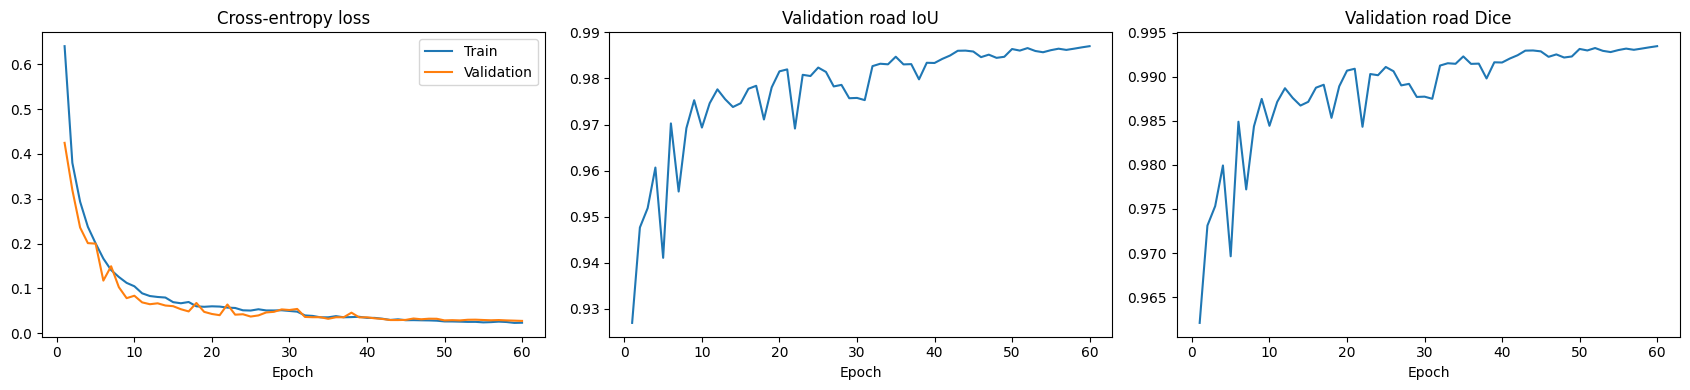

In [12]:
# 12. Vẽ learning curves
import pandas as pd

if HISTORY_CSV.exists():
    history_df = pd.read_csv(HISTORY_CSV)
    display(history_df.tail())

    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
    axes[0].set_title("Cross-entropy loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    
    axes[1].plot(history_df["epoch"], history_df["val_road_iou"])
    axes[1].set_title("Validation road IoU")
    axes[1].set_xlabel("Epoch")
    
    axes[2].plot(history_df["epoch"], history_df["val_road_dice"])
    axes[2].set_title("Validation road Dice")
    axes[2].set_xlabel("Epoch")
    
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có history CSV. Hãy chạy cell huấn luyện trước.")


In [13]:
# 13. Nạp best checkpoint và đánh giá lại trên validation
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError("Chưa có best_model.pth. Hãy chạy cell huấn luyện trước.")

best_checkpoint = torch.load(BEST_CHECKPOINT, map_location=DEVICE)
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

final_val_metrics = run_epoch(val_loader, training=False)
print("Validation metrics của best checkpoint:")
for key, value in final_val_metrics.items():
    print(f"{key:>18}: {value:.4f}")


Validation:   0%|          | 0/73 [00:00<?, ?it/s]

Validation metrics của best checkpoint:
    background_iou: 0.9872
          road_iou: 0.9870
          mean_iou: 0.9871
    pixel_accuracy: 0.9935
    road_precision: 0.9930
       road_recall: 0.9939
         road_dice: 0.9935
              loss: 0.0278


In [14]:
# EXPORT TWINLITENET ROAD SEGMENTATION TO ONNX
!pip install onnx==1.14.0 onnxscript==0.1.0 onnx-ir==0.1.0
import torch
import torch.nn as nn
import onnx
from pathlib import Path

# 1. Kiểm tra checkpoint
if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(f"Không tìm thấy: {BEST_CHECKPOINT}")

# 2. Load best checkpoint
checkpoint = torch.load(BEST_CHECKPOINT, map_location="cpu")

export_model = TwinLiteNet()
export_model.load_state_dict(checkpoint["model_state_dict"])
export_model.eval()


# 3. Wrapper: chỉ xuất đầu ra Drivable Area (DA)
class TwinLiteDAExport(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        da_logits, ll_logits = self.model(x)
        return da_logits


onnx_model = TwinLiteDAExport(export_model)
onnx_model.eval()

# 4. Input cố định: Batch=1, RGB, 360x640
dummy_input = torch.randn(
    1, 3, IMAGE_HEIGHT, IMAGE_WIDTH,
    dtype=torch.float32
)

# 5. Đường dẫn lưu ONNX
ONNX_PATH = OUTPUT_DIR / "twinlite_road_da.onnx"

# 6. Export ONNX
torch.onnx.export(
    onnx_model,
    dummy_input,
    str(ONNX_PATH),
    export_params=True,
    opset_version=11,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["da_logits"],
    dynamo=False  # Thêm dòng này
)

# 7. Kiểm tra file ONNX
onnx_graph = onnx.load(str(ONNX_PATH))
onnx.checker.check_model(onnx_graph)

print("ONNX export thành công!")
print("Model:", ONNX_PATH)
print("Input shape:  [1, 3, 320, 184]")
print("Output shape: [1, 2, 320, 184]")
print("Opset:", 11)
print("Checkpoint:", BEST_CHECKPOINT)

  Using cached onnx-1.14.0.tar.gz (11.3 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached onnxscript-0.1.0-py3-none-any.whl.metadata (15 kB)
  Using cached onnx_ir-0.1.0-py3-none-any.whl.metadata (4.6 kB)
INFO: pip is looking at multiple versions of onnxscript to determine which version is compatible with other requirements. This could take a while.
ERROR: Cannot install onnx==1.14.0 and onnxscript==0.1.0 because these package versions have conflicting dependencies.

The conflict is caused by:
    The user requested onnx==1.14.0
    onnxscript 0.1.0 depends on onnx>=1.16

Additionally, some packages in these conflicts have no matching distributions available for your environment:
    onnx

To fix this you could try to:
1. loosen the range of package versions you've specified
2. remove package versions to allow pip to attempt to solve the dep

/tmp/ipykernel_550/3231946524.py:44: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX export thành công!
Model: /kaggle/working/twinlite_road_training/twinlite_road_da.onnx
Input shape:  [1, 3, 320, 184]
Output shape: [1, 2, 320, 184]
Opset: 11
Checkpoint: /kaggle/working/twinlite_road_training/best_model.pth


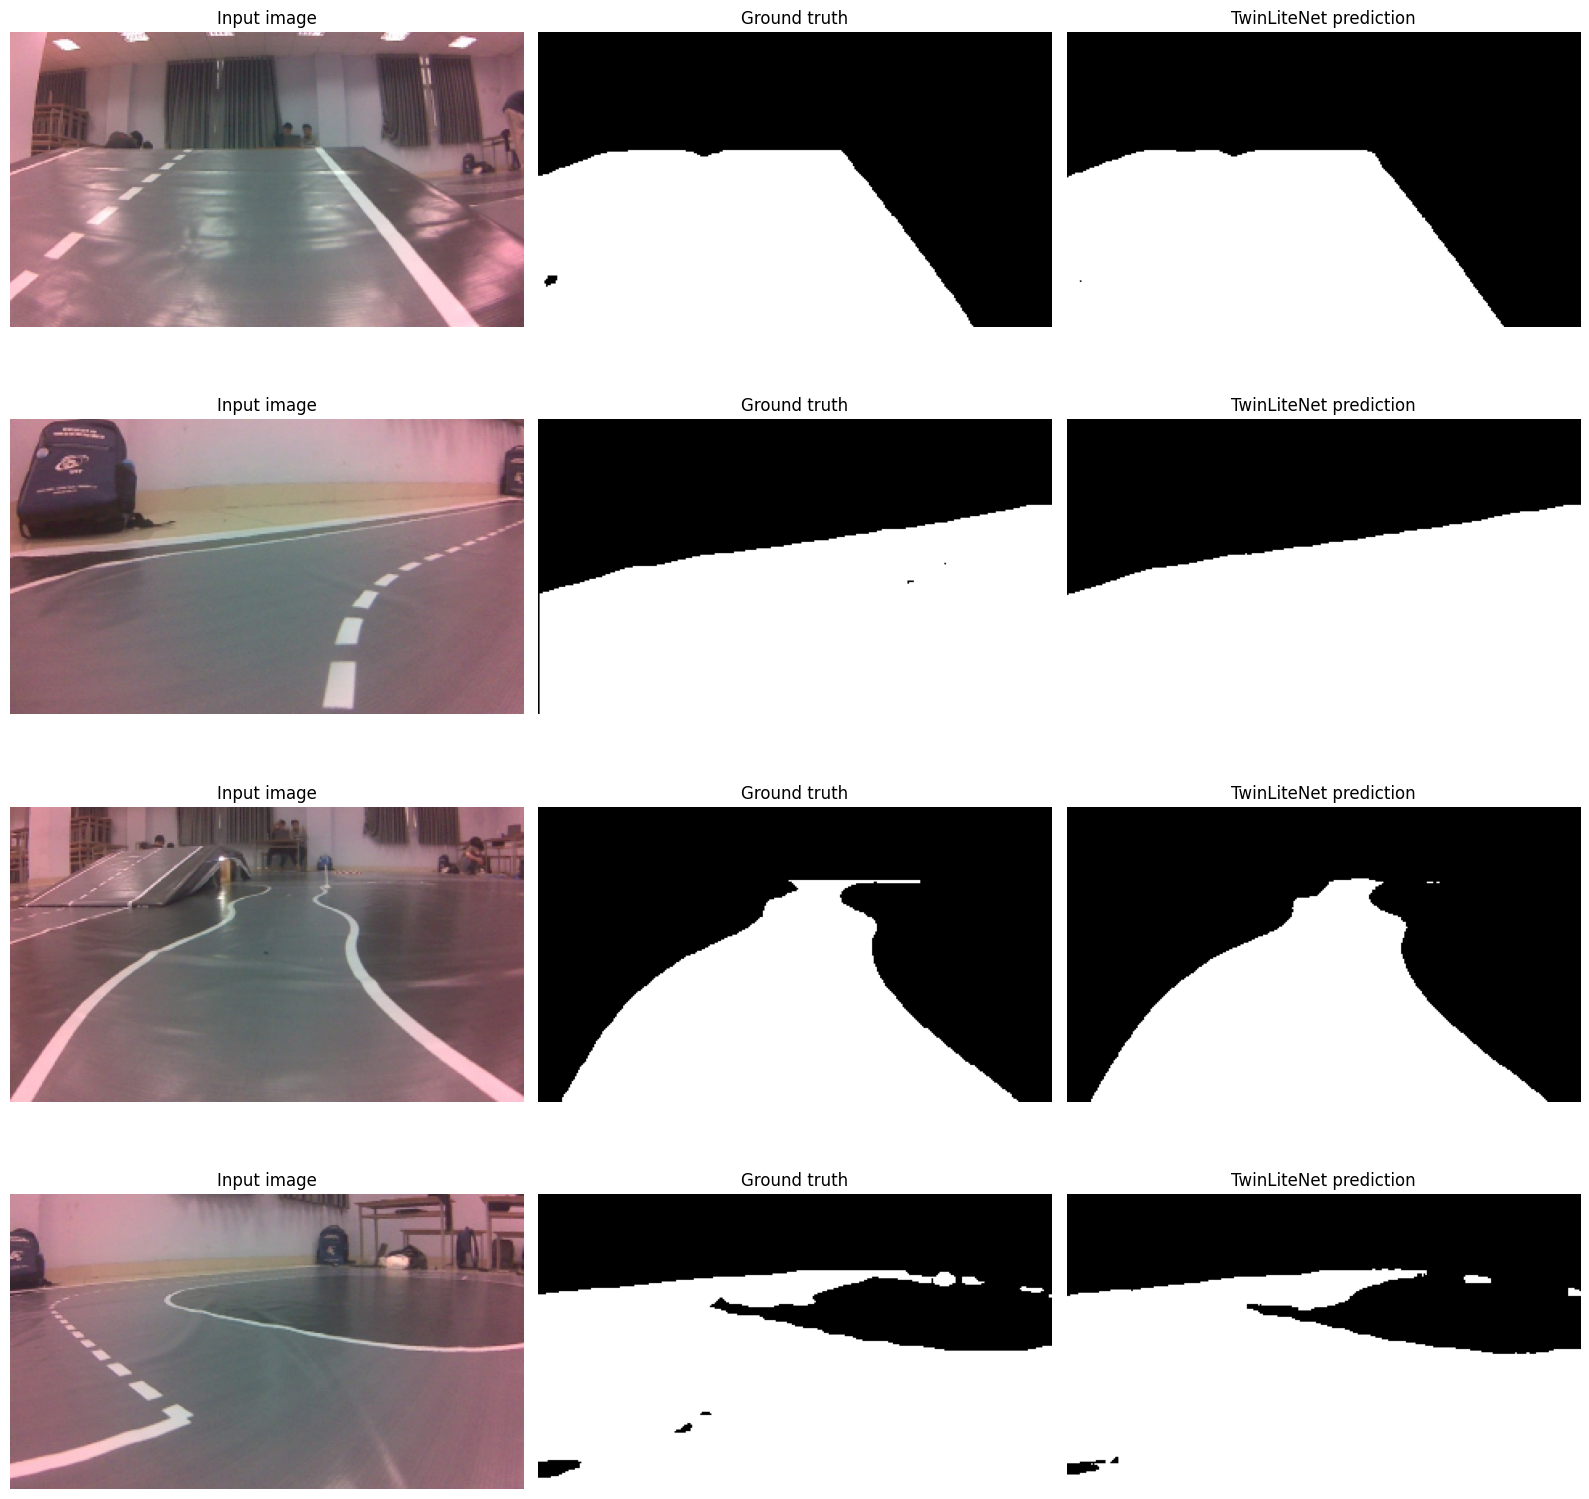

In [15]:
# 14. Hiển thị dự đoán trên một số ảnh validation
@torch.no_grad()
def predict_mask(image_tensor):
    model.eval()
    logits = model(image_tensor.unsqueeze(0).to(DEVICE))[0]
    pred = torch.argmax(logits, dim=1)[0]
    return (pred.cpu().numpy().astype(np.uint8) * 255)

n_show = min(4, len(val_dataset))
fig, axes = plt.subplots(n_show, 3, figsize=(16, 4 * n_show))
if n_show == 1:
    axes = np.expand_dims(axes, axis=0)

for i in range(n_show):
    image_tensor, gt_mask = val_dataset[i]
    image_rgb = (image_tensor.permute(1, 2, 0).numpy() * 255).clip(0, 255).astype(np.uint8)
    pred_mask = predict_mask(image_tensor)

    axes[i, 0].imshow(image_rgb)
    axes[i, 0].set_title("Input image")
    axes[i, 1].imshow(gt_mask.numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title("Ground truth")
    axes[i, 2].imshow(pred_mask, cmap="gray", vmin=0, vmax=255)
    axes[i, 2].set_title("TwinLiteNet prediction")
    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [16]:
# 15. Lưu mask dự đoán của toàn bộ validation
PREDICTION_DIR = OUTPUT_DIR / "validation_predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

for i, (image_path, _) in enumerate(val_pairs):
    image_tensor, _ = val_dataset[i]
    pred_mask = predict_mask(image_tensor)
    output_path = PREDICTION_DIR / f"{image_path.stem}_pred.png"
    cv2.imwrite(str(output_path), pred_mask)

print("Đã lưu mask dự đoán tại:", PREDICTION_DIR)
print("Các file kết quả:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path)


Đã lưu mask dự đoán tại: /kaggle/working/twinlite_road_training/validation_predictions
Các file kết quả:
/kaggle/working/twinlite_road_training/best_model.pth
/kaggle/working/twinlite_road_training/last_checkpoint.pth
/kaggle/working/twinlite_road_training/training_history.csv
/kaggle/working/twinlite_road_training/twinlite_road_da.onnx
/kaggle/working/twinlite_road_training/validation_predictions


Loading ONNX model from: /kaggle/working/twinlite_road_training/twinlite_road_da.onnx
Model Input Shape: [1, 3, 184, 320] (Height=184, Width=320)
Model Output Name: da_logits


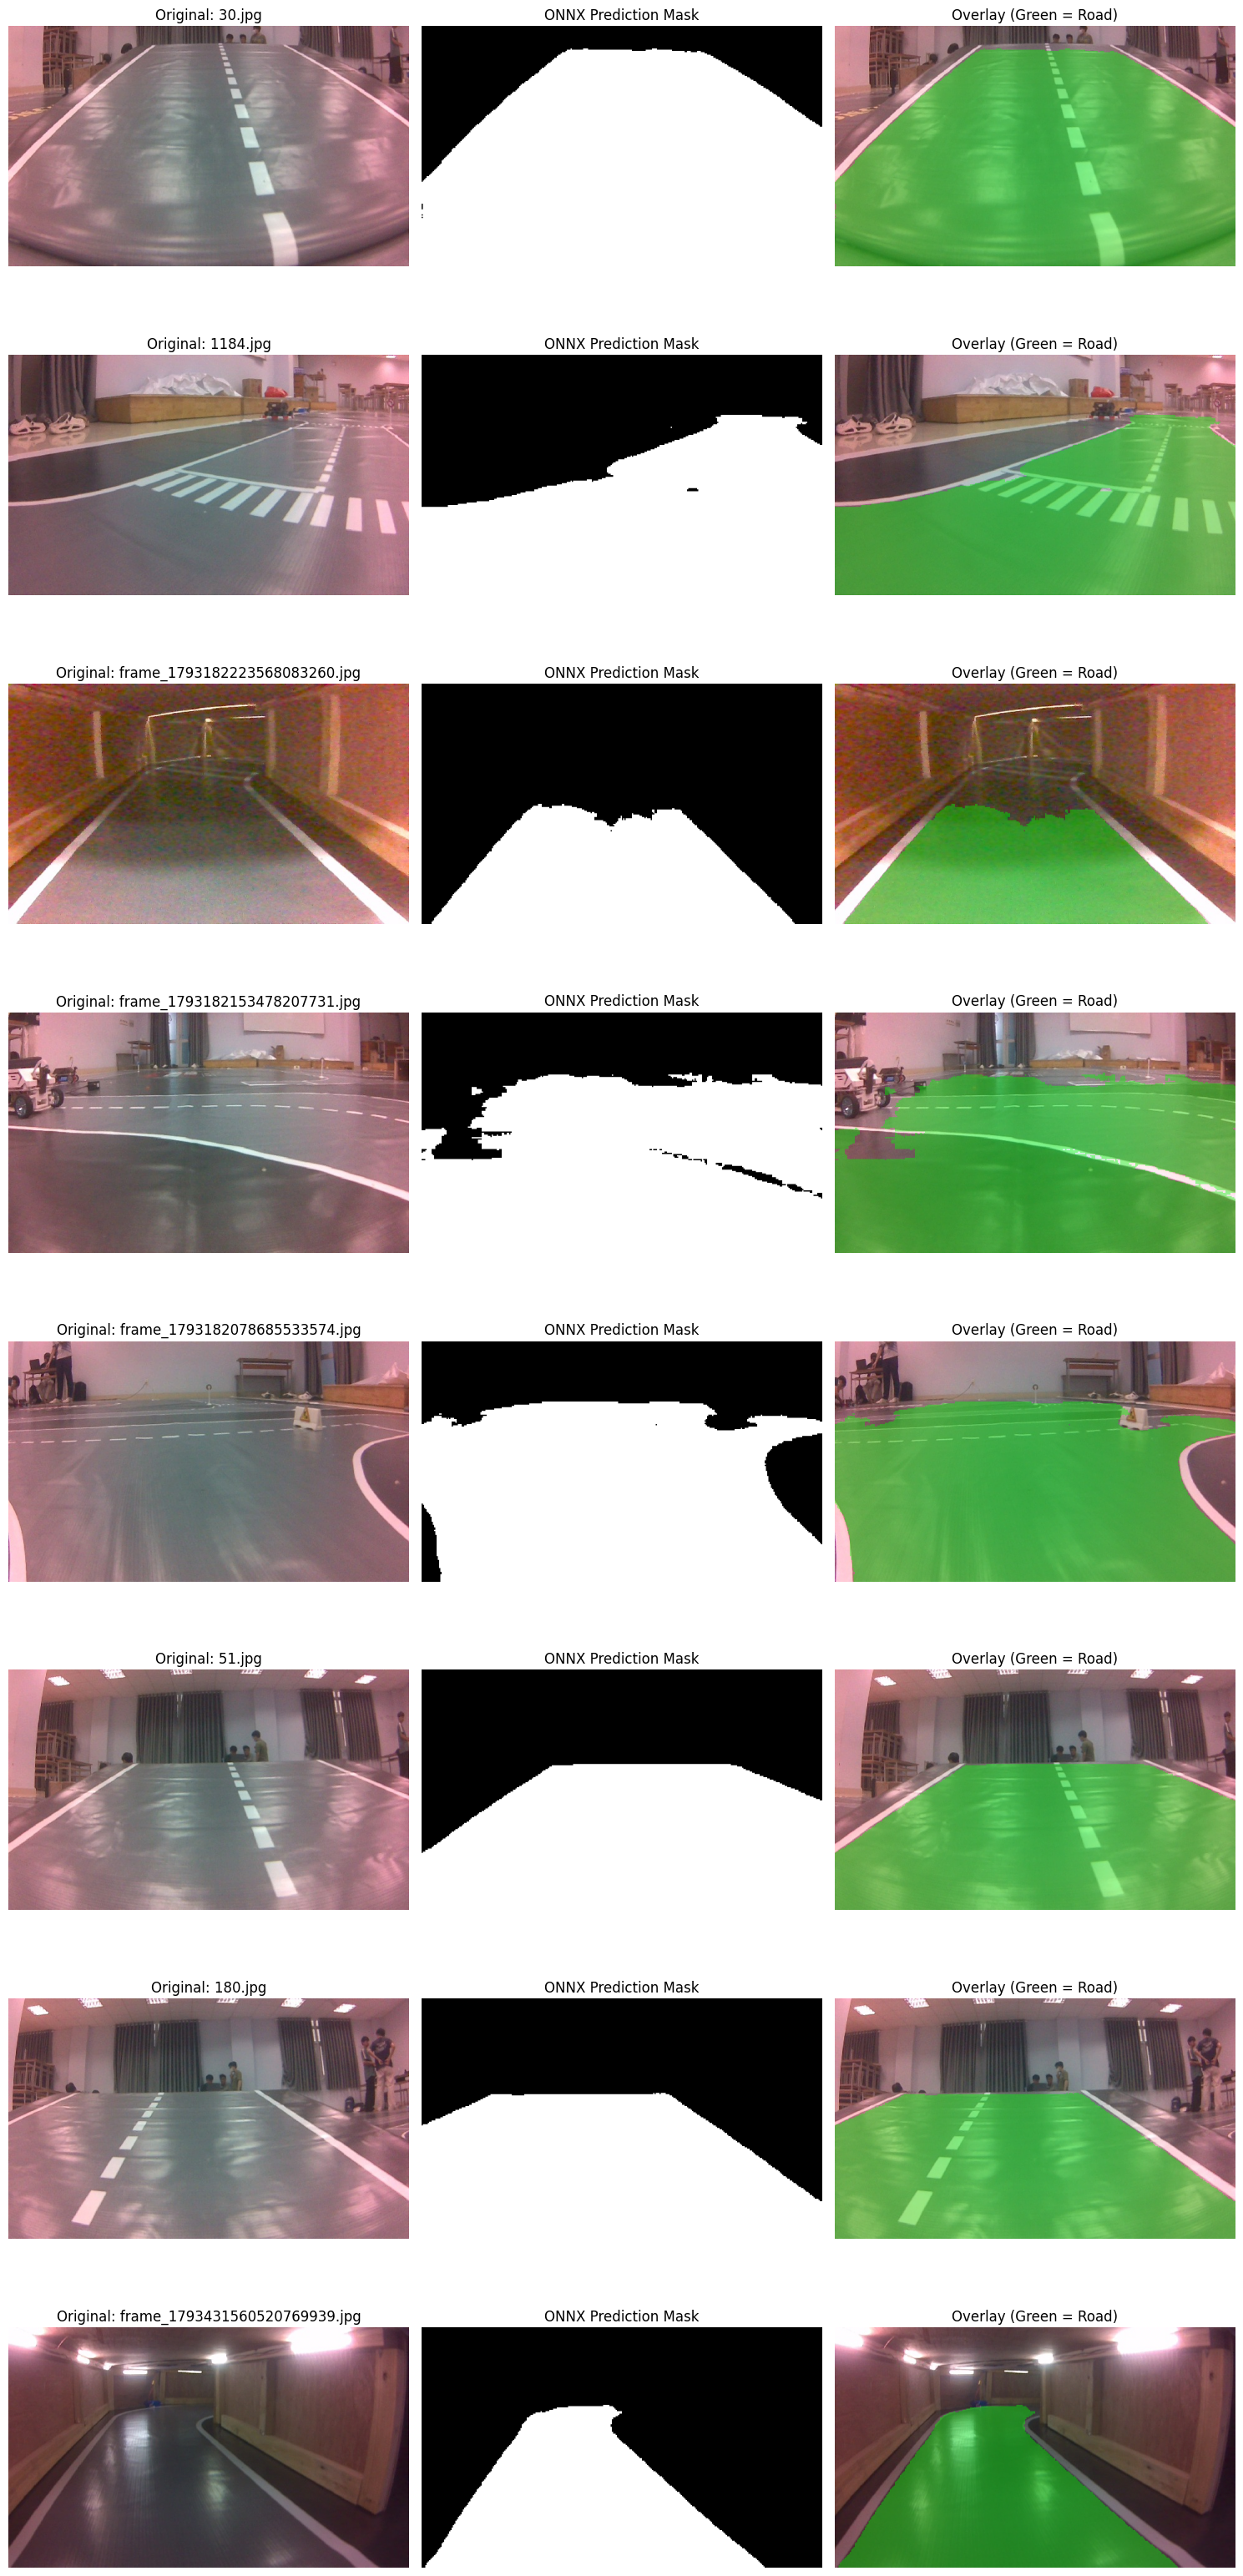

✅ Đã chạy xong test ONNX. Hãy kiểm tra chất lượng mask bằng mắt!


In [17]:
# Cài đặt thư viện nếu chưa có
!pip install onnxruntime -q

import os
import cv2
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt
import glob
import random

# ============================================================
# CẤU HÌNH ĐƯỜNG DẪN
# ============================================================
# Đường dẫn tới file ONNX vừa export
ONNX_PATH = "/kaggle/working/twinlite_road_training/twinlite_road_da.onnx"

# Đường dẫn tới thư mục chứa ảnh test (bạn có thể trỏ tới tập test/val)
IMG_DIR = "/kaggle/input/datasets/tamkhanh/label-v3/test/road-v2" 

# Số lượng ảnh muốn hiển thị để test
NUM_TEST_IMAGES = 8

# ============================================================
# KHỞI TẠO MÔ HÌNH ONNX RUNTIME
# ============================================================
print(f"Loading ONNX model from: {ONNX_PATH}")
session = ort.InferenceSession(ONNX_PATH, providers=['CPUExecutionProvider'])

# Lấy thông tin Input
input_name = session.get_inputs()[0].name
input_shape = session.get_inputs()[0].shape
INPUT_H, INPUT_W = input_shape[2], input_shape[3]
print(f"Model Input Shape: {input_shape} (Height={INPUT_H}, Width={INPUT_W})")

# Lấy thông tin Output
output_name = session.get_outputs()[0].name
print(f"Model Output Name: {output_name}")

# ============================================================
# HÀM TIỀN XỬ LÝ VÀ SUY LUẬN
# ============================================================
def process_image(img_path):
    # 1. Đọc ảnh (BGR)
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        return None, None, None
        
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    original_h, original_w = img_rgb.shape[:2]

    # 2. Resize về kích thước mô hình yêu cầu
    img_resized = cv2.resize(img_rgb, (INPUT_W, INPUT_H), interpolation=cv2.INTER_LINEAR)

    # 3. Chuẩn hóa (Normalize) về [0, 1] và chuyển sang CHW
    img_norm = img_resized.astype(np.float32) / 255.0
    img_chw = np.transpose(img_norm, (2, 0, 1)) # HWC -> CHW
    img_batch = np.expand_dims(img_chw, axis=0) # Thêm batch dimension: [1, 3, H, W]

    # 4. Chạy Inference
    outputs = session.run([output_name], {input_name: img_batch})
    out_logits = outputs[0] # Shape: [1, 2, H, W]

    # 5. Hậu xử lý: Lấy argmax trên 2 class (0: Nền, 1: Đường)
    # out_logits[0] có shape [2, H, W]
    pred_mask = np.argmax(out_logits[0], axis=0).astype(np.uint8) * 255 # Shape: [H, W]

    # 6. Resize mask về kích thước ảnh gốc để dễ hiển thị
    pred_mask_resized = cv2.resize(pred_mask, (original_w, original_h), interpolation=cv2.INTER_NEAREST)

    return img_rgb, pred_mask_resized, img_bgr

# ============================================================
# CHẠY TEST VÀ HIỂN THỊ
# ============================================================
# Lấy ngẫu nhiên một số ảnh để test
all_files = glob.glob(os.path.join(IMG_DIR, "*.jpg"))
test_files = random.sample(all_files, min(NUM_TEST_IMAGES, len(all_files)))

fig, axes = plt.subplots(len(test_files), 3, figsize=(15, 4 * len(test_files)))
if len(test_files) == 1: axes = np.expand_dims(axes, axis=0)

for i, img_path in enumerate(test_files):
    fname = os.path.basename(img_path)
    img_rgb, mask, img_bgr = process_image(img_path)

    if img_rgb is None:
        print(f"❌ Lỗi đọc ảnh: {img_path}")
        continue

    # Tạo Overlay
    overlay = img_rgb.copy()
    overlay[mask > 127] = (0, 255, 0) # Tô màu xanh lá lên vùng đường
    blended = cv2.addWeighted(img_rgb, 0.6, overlay, 0.4, 0)

    # Hiển thị
    axes[i][0].imshow(img_rgb)
    axes[i][0].set_title(f"Original: {fname}")
    axes[i][0].axis('off')

    axes[i][1].imshow(mask, cmap='gray')
    axes[i][1].set_title("ONNX Prediction Mask")
    axes[i][1].axis('off')

    axes[i][2].imshow(blended)
    axes[i][2].set_title("Overlay (Green = Road)")
    axes[i][2].axis('off')

plt.tight_layout()
plt.show()

print("✅ Đã chạy xong test ONNX. Hãy kiểm tra chất lượng mask bằng mắt!")

## Kết quả và lưu ý sử dụng

Các file chính được lưu trong `/kaggle/working/twinlite_road_training/`:

- `best_model.pth`: checkpoint có **validation road IoU cao nhất**.
- `last_checkpoint.pth`: checkpoint của epoch gần nhất, dùng để resume.
- `training_history.csv`: loss và metric theo epoch.
- `validation_predictions/`: mask dự đoán trên tập validation.

### Một số điểm cần kiểm tra sau khi train

1. So sánh dự đoán với ground truth ở cell 14. IoU cao nhưng mask trực quan sai vẫn cần điều tra lại nhãn hoặc cách chia dữ liệu.
2. Kiểm tra mask gốc: vùng đường phải trắng, nền phải đen. Notebook cố ý không tự động đảo mask theo tỷ lệ pixel, vì cách đó có thể đảo nhầm những ảnh có diện tích đường lớn.
3. Kết quả validation chỉ là ước lượng nội bộ vì dữ liệu ban đầu chỉ có một thư mục `test` đã được tách ra để train/validation.
4. Nhánh `LL` không được huấn luyện vì không có nhãn lane-line. Đây là bài toán Drivable Area nhị phân, không phải mô hình đa nhiệm DA+LL hoàn chỉnh.
5. Nếu Kaggle hết RAM GPU, giảm `BATCH_SIZE` xuống `2`. Nếu clone repo thất bại, bật Internet trong phần Notebook Settings.

Nguồn mã model: [TwinLiteNet GitHub](https://github.com/chequanghuy/TwinLiteNet), đặc biệt `model/TwinLite.py`, `DataSet.py` và `test_image.py`.


### Quy tắc xử lý dữ liệu chưa gán nhãn

- Ảnh không có mask cùng stem (ví dụ `200.jpg` không có `200_mask.png`) được xem là ảnh chưa gán nhãn và **không** đưa vào train/validation.
- Mask không có ảnh tương ứng được xem là file dư và bị bỏ qua.
- Với thống kê người dùng cung cấp: 4.665 ảnh, 1.497 mask, 1.455 cặp khớp. Nếu tất cả cặp đều đọc được, chia 80/20 sẽ cho 1.164 cặp train và 291 cặp validation. Notebook sẽ tính lại số thực tế sau khi kiểm tra file.
